Số lượng thành phần liên thông có diện tích > 200 px: 6


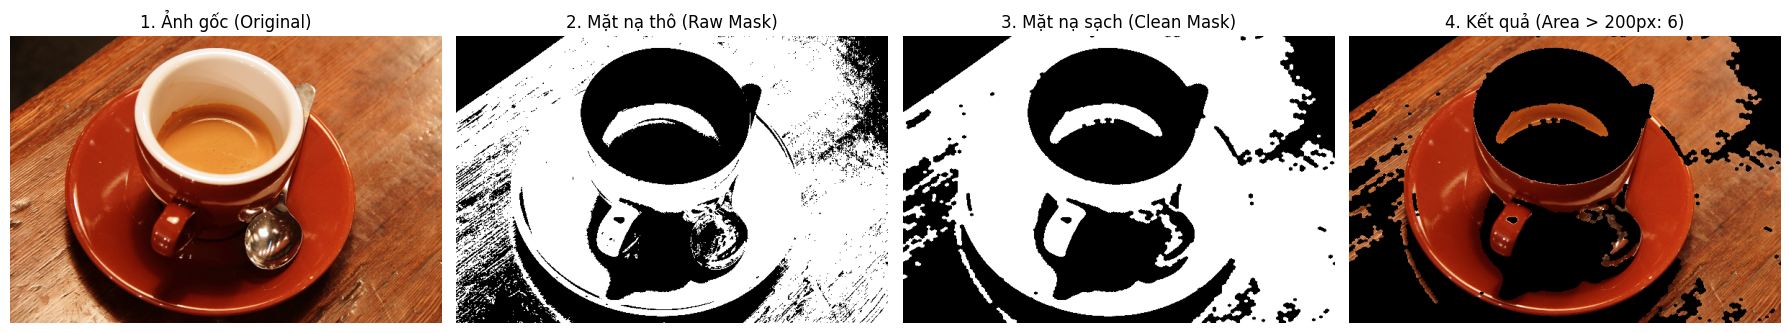

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# 1. Đọc ảnh mẫu coffee()
img = data.coffee()

# 2. Chuyển đổi không gian màu sang HSV
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

# 3. Phân đoạn vùng màu đỏ - cam bằng cv2.inRange (xử lý 2 đầu trục H)
m1 = cv2.inRange(hsv, (0, 80, 60), (12, 255, 255))
m2 = cv2.inRange(hsv, (165, 80, 60), (179, 255, 255))
mask_raw = m1 | m2

# 4. Làm sạch mặt nạ bằng phép mở rồi đóng (kernel hình elip 5x5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel)
mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel)

# 5. Phân tích thành phần liên thông với connectedComponentsWithStats
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)

# 6. Đếm và lọc thành phần liên thông có diện tích > 200 px (loại bỏ nền index 0)
mask_filtered = np.zeros_like(mask_clean)
count_components = 0

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    if area > 200:
        mask_filtered[labels == i] = 255
        count_components += 1

print(f"Số lượng thành phần liên thông có diện tích > 200 px: {count_components}")

# 7. Trích xuất kết quả ảnh màu theo mặt nạ đã lọc
result = cv2.bitwise_and(img, img, mask=mask_filtered)

# 8. Hiển thị 4 ảnh: gốc, mặt nạ thô, mặt nạ sạch, kết quả
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img)
axes[0].set_title("1. Ảnh gốc (Original)")
axes[0].axis("off")

axes[1].imshow(mask_raw, cmap="gray")
axes[1].set_title("2. Mặt nạ thô (Raw Mask)")
axes[1].axis("off")

axes[2].imshow(mask_clean, cmap="gray")
axes[2].set_title("3. Mặt nạ sạch (Clean Mask)")
axes[2].axis("off")

axes[3].imshow(result)
axes[3].set_title(f"4. Kết quả (Area > 200px: {count_components})")
axes[3].axis("off")

plt.tight_layout()
plt.show()